# Week 7 practical: Baird's star and a DQN ablation

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** In Google Colab: open colab.research.google.com, then File > Upload
notebook, and pick this `.ipynb`. Nothing to install. Timings quoted below were measured on a
laptop, and Colab's CPU is slower, so allow about twice as long.

In Week 6, we learned $Q$ using a table, and all the convergence guarantees established in Weeks 3–6 still applied. Today, we move beyond tabular methods and introduce function approximation.

The first half of the session studies the smallest counterexample to the stability of off-policy learning with function approximation: Baird's star. It has just seven states, eight linear weights and zero reward everywhere, yet a familiar update rule makes the estimated values explode. You will derive the expected update, watch the values grow towards $10^{60}$, and identify the cause through an eigenvalue analysis, before drawing a single sample.

In the second half, we bring a neural network to the swing-up problem from Week 6. You will implement DQN, switch its stabilising mechanisms on and off, and compare its performance against the exact optimum. Along the way, you will write the bootstrap target and see where the three ingredients of the deadly triad—bootstrapping, off-policy learning and function approximation—come together.

## Objectives

1. Compute the expected semi-gradient update on Baird's star as a linear system and read its
   stability off the eigenvalues of $A$, off-policy and on-policy.
2. Implement off-policy semi-gradient TD(0) with linear features, reproduce the divergence, and
   show that removing any one ingredient of the triad stops it.
3. Measure what a smaller step size does to the divergence.
4. Implement the DQN temporal-difference error with a target network and the double-DQN switch,
   and check it against the hand trace of the notes.
5. Run the four-way DQN algorithm on the swing-up, read each stabiliser's worth off the exact
   value of the policy the network induces, and compare it with a table on the same budget.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, Baird's star and its eigenvalues (Checkpoint 1) | 12 |
| 4. Blanked core A, the off-policy semi-gradient TD update (Checkpoint 2) | 10 |
| 5. The divergence, and one ingredient removed at a time (Checkpoint 3) | 8 |
| 6. A smaller step size (Checkpoint 4) | 4 |
| 7. Blanked core B, the DQN TD error, the hand trace and the bias of a max (Checkpoint 5) | 15 |
| 8. The DQN ablation on the swing-up, and a table on the same budget (Checkpoint 6) | 22 |
| 9. Analysis | 4 |
| The quiz, on the university course page | 15 |

One cell is heavy. Section 8 trains twenty networks for $6 \times 10^4$
transitions each and takes about three minutes on a laptop, so up to six in Colab. Start it, then
read the markdown under it while it runs. Everything else finishes in a few seconds. Exercises 7.4
and 7.5 of the notes take the linear algebra of sections 3 to 6 further, and the challenge problem
7.6 prices the guaranteed alternatives. All three are formative, so nobody collects them.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import matplotlib
import matplotlib.pyplot as plt
import torch

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"torch       {torch.__version__}")

# One random rollout: the course pendulum (m = l = 1, b = 0.1, u_max = 5 < m g l) released near
# the bottom under random saturated torques for 5 s. Section 8 builds the swing-up chain from it.
rng = np.random.default_rng(0)
th, om = 0.1, 0.0
for _ in range(50):
    u = np.clip(rng.normal(0.0, 3.0), -5.0, 5.0)
    for _ in range(10):
        om += 0.01 * (u - 0.1 * om - 9.81 * np.sin(th))
        th += 0.01 * om
print(f"\none random rollout: final angle {th:+.3f} rad, final rate {om:+.3f} rad/s")

# One forward and backward pass through a small network, the operation section 8 repeats.
net = torch.nn.Sequential(torch.nn.Linear(3, 48), torch.nn.ReLU(), torch.nn.Linear(48, 5))
net(torch.randn(32, 3)).pow(2).mean().backward()
print(f"one torch gradient step: OK, {sum(p.numel() for p in net.parameters())} parameters")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.18
numpy       2.4.6
scipy       1.16.3
matplotlib  3.10.0
torch       2.11.0+cpu

one random rollout: final angle +1.087 rad, final rate -0.515 rad/s
one torch gradient step: OK, 437 parameters

setup OK  (8.4 s)


## 2. Recap

With linear features $V_w(x) = \phi(x)^\top w$, the TD update of Week 5 moves the weight vector
along the feature direction (notes section 2.1, eq. 3),

$$ w \leftarrow w + \alpha\,\rho\,\delta\,\phi(x), \qquad
   \delta = r + \gamma\,\phi(x')^\top w - \phi(x)^\top w , $$

where the importance ratio $\rho = \pi(u\mid x)/\beta(u\mid x)$ reweights a transition collected
by the behaviour policy $\beta$ so that it can be used for the target policy $\pi$. The target is
held fixed when differentiating, so this is a semi-gradient (notes section 2.2). On average the
update is the linear iteration $w \leftarrow w + \alpha(b - Aw)$ with
$A = \Phi^\top D(I - \gamma P)\Phi$ (notes section 3.2, eq. 13), where $D$ weights states by how
often the data visit them and $P$ is the kernel of the policy being evaluated. That iteration is
forward Euler on $\dot w = b - Aw$, so it is stable exactly when every eigenvalue of $A$ has
positive real part. DQN (notes sections 4.3 and 4.4, eq. 16 and Algorithm 2) keeps all three
ingredients of the triad and adds a replay buffer, a target network, and, as double DQN, a split
of the $\max$ into selection and evaluation (notes section 4.5, eq. 17).

Background reading: notes sections 2.1 and 2.2 (the semi-gradient update), 3.1 and 3.2 (the
deadly triad, Baird's star and figure `baird_counterexample_divergence`), 3.3 (where the tabular
argument broke), 4.3 to 4.7 (DQN, its hand trace, double DQN, table 1 and figure
`dqn_replay_ablation`), 4.8 (honest accounting), and the concept notes `Deadly triad`,
`Baird's counterexample`, `Semi-gradient update`, `Off-policy learning`, `DQN`,
`Experience replay`, `Target network` and `Maximisation bias`.

## 3. Baird's star, and its expected update

The construction of notes section 3.2 (figure `baird_star`), built exactly as
`09_Code/Week07/baird_star.m` builds it. States 0 to 5 are the upper states and state 6 is the
lower one. The dashed action jumps to one of the six upper states uniformly, and the solid action
jumps to state 6. The features are

$$ V_w(i) = 2w_i + w_7 \quad (i = 0,\dots,5), \qquad V_w(6) = w_6 + 2w_7 , $$

eight weights for seven states, with the eighth weight $w_7$ shared by every state. Every reward
is zero, so $V^\pi = 0$, which $w = 0$ represents exactly. The behaviour policy takes the dashed
action with probability $6/7$, which makes the state distribution uniform. The target policy
always takes the solid action, so $\rho = 0$ on dashed and $\rho = 7$ on solid. The run starts from
$w_0 = (1,1,1,1,1,1,10,1)$, a value function of $(3,3,3,3,3,3,12)$, with $\gamma = 0.99$.

The cell builds $A$ twice. Off-policy, $D$ is the uniform distribution of the behaviour data and
$P$ is the solid-action kernel of the target policy. On-policy, the policy being evaluated is the
behaviour policy itself, so $P$ is its kernel and $D$ is its stationary distribution, which is the
same uniform $D$. Nothing is sampled here. The eigenvalues are computed.

initial value function V = PHI w0 : [ 3.  3.  3.  3.  3.  3. 12.]
real parts of eig(A), off-policy  : [-0.239 -0.022  0.     0.571  0.571  0.571  0.571  0.571]
real parts of eig(A), on-policy   : [0.    0.016 0.329 0.571 0.571 0.571 0.571 0.571]

predicted growth per expected update at alpha = 0.01: 1 - alpha * lambda_min = 1.0024


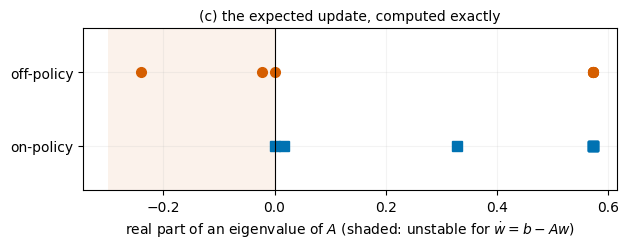

In [ ]:
N_S, N_W, GAMMA_B = 7, 8, 0.99

PHI = np.zeros((N_S, N_W))
for i in range(6):
    PHI[i, i], PHI[i, 7] = 2.0, 1.0                 # upper state i: 2 w_i + w_7
PHI[6, 6], PHI[6, 7] = 1.0, 2.0                     # lower state:   w_6 + 2 w_7

P_DASH = np.zeros((N_S, N_S))
P_DASH[:, :6] = 1 / 6                               # dashed: to an upper state, uniformly
P_SOLID = np.zeros((N_S, N_S))
P_SOLID[:, 6] = 1.0                                 # solid: to the lower state
BEHAV = np.array([6 / 7, 1 / 7])                    # behaviour: P(dashed), P(solid)
RHO = np.array([0.0, 1.0]) / BEHAV                  # target always solid: rho = 0 and 7
P_BEHAV = BEHAV[0] * P_DASH + BEHAV[1] * P_SOLID
D_UNIF = np.eye(N_S) / N_S                          # the behaviour chain's stationary distribution
W0 = np.array([1, 1, 1, 1, 1, 1, 10, 1], dtype=float)

A_OFF = PHI.T @ D_UNIF @ (np.eye(N_S) - GAMMA_B * P_SOLID) @ PHI    # data uniform, evaluate solid
A_ON = PHI.T @ D_UNIF @ (np.eye(N_S) - GAMMA_B * P_BEHAV) @ PHI     # data and evaluation agree

eig_off = np.sort(np.linalg.eigvals(A_OFF).real)
eig_on = np.sort(np.linalg.eigvals(A_ON).real)
print("initial value function V = PHI w0 :", PHI @ W0)
print("real parts of eig(A), off-policy  :", eig_off.round(3) + 0.0)
print("real parts of eig(A), on-policy   :", eig_on.round(3) + 0.0)
LAM_MIN = eig_off[0]
print(f"\npredicted growth per expected update at alpha = 0.01: 1 - alpha * lambda_min = "
      f"{1 - 0.01 * LAM_MIN:.4f}")

fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.axvspan(-0.3, 0.0, color="#D55E00", alpha=0.08, lw=0)
ax.plot(eig_off, np.full(N_W, 1.0), "o", color="#D55E00", ms=7, label="off-policy")
ax.plot(eig_on, np.full(N_W, 0.0), "s", color="#0072B2", ms=7, label="on-policy")
ax.axvline(0.0, color="k", lw=0.8)
ax.set_yticks([0, 1], ["on-policy", "off-policy"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel(r"real part of an eigenvalue of $A$ (shaded: unstable for $\dot w = b - Aw$)")
ax.set_title("(c) the expected update, computed exactly", fontsize=10)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Checkpoint 1

Examine the eigenvalues of $A$ in the off-policy and on-policy cases. Which eigenvalues have negative real parts in the off-policy case? Do they remain negative when the data are generated on-policy? Using the most negative eigenvalue found off-policy, calculate the growth factor of the corresponding mode after one expected TD update with step size $\alpha=0.01$.

### Answer Checkpoint 1

* **Which eigenvalues have negative real parts in the off-policy case?**
  The eigenvalues with negative real parts under off-policy learning are approximately **$-0.239$** and **$-0.022$**. These negative eigenvalues represent unstable modes (exponential growth) in the continuous-time system $\dot{w} = b - Aw$, causing the parameter updates to explode.

* **Do they remain negative when the data are generated on-policy?**
  **No!** In the on-policy case, all eigenvalues are non-negative (`[0.0, 0.016, 0.329, 0.571, ...]`). With no negative real parts, the system remains stable and does not diverge.

* **Why is the 0.0 eigenvalue marginally stable (rather than growing)?**
  Your intuition is exactly correct! In linear dynamical systems $\dot{w} = -Aw$, the behavior of modes depends on $e^{-\lambda t}$. When $\lambda = 0.0$, the growth/decay factor is $e^0 = 1$. This means the error along this mode neither shrinks nor grows—it remains constant (marginally stable).

* **Growth factor after one expected update at $\alpha = 0.01$:**
  Using the most negative eigenvalue ($\lambda_{min} \approx -0.23925$):
  $$\text{Growth Factor} = 1 - \alpha \lambda_{min} = 1 - 0.01 \times (-0.23925) = \mathbf{1.0024}$$
  This confirms that each expected update scales the magnitude of the unstable mode by **$1.0024$**, leading to exponential growth over time.

---

### 🧠 Simplified Intuition (What is actually going on?)

* **The Shared Weight Trap (The Copycat Effect):**
  All states share a single weight ($w_7$). This is like a group of friends copying each other. If you change the score for one state, **every other state's score changes too**, even when it shouldn't!

* **On-Policy vs. Off-Policy:**
  * **On-Policy (Safe & Balanced):** You learn from your own actual experience. This keeps your updates grounded and prevents scores from spinning out of control.
  * **Off-Policy (The Hype Loop):** You use random data to guess the value of a greedy strategy. Because of the shared weight, updating one state inflates the guess for the next state, which feeds back and inflates the first state again. It's a never-ending hype loop!

* **The Power of Compound Interest ($1.0024$):**
  Growing by $1.0024$ (or $0.24\%$) per step sounds tiny. But just like putting money in a high-interest savings account, if you multiply it over **60,000 steps**, that tiny growth compounds into a massive, astronomical number that breaks your system!

## 4. Off-policy semi-gradient TD(0)

Implement the TD update from the recap for a single transition $ (x,u,r,x') $ collected by the behaviour policy.

The function receives the current weight vector `w`, the feature vectors `phi_x` and `phi_next` corresponding to $\phi(x)$ and $\phi(x')$, and `rho`, the importance-sampling ratio for the action taken. It must return the updated weight vector without modifying the input `w`.

Use the same implementation throughout Sections 5 and 6. It must also support the tabular case: the runner handles this by passing rows of the identity matrix as feature vectors.

In [ ]:
def semi_gradient_td(w, phi_x, phi_next, reward, rho, alpha, gamma):
    """One off-policy semi-gradient TD(0) step with linear features. Returns the new weights."""
    # ===== YOUR CODE HERE (≈2 lines) ============================
    # Goal: delta = r + gamma phi(x')^T w - phi(x)^T w, then return w + alpha rho delta phi(x)
    delta = reward + gamma * (phi_next @ w) - (phi_x @ w)
    updated_weights = w + alpha * rho * delta * phi_x
    return updated_weights
    # Hint: notes eq. 3 (section 2.1), with the importance ratio of the recap as one more factor
    # ============================================================

### A test: one update aimed at one state

A solid transition from upper state 0 to the lower state, from $w_0$, at $\alpha = 0.01$. The TD
error is $0 + 0.99 \times 12 - 3 = 8.88$, and the ratio is 7. The cell prints the value of every
state before and after.

In [ ]:
w1 = semi_gradient_td(W0, PHI[0], PHI[6], 0.0, RHO[1], 0.01, GAMMA_B)
assert np.allclose(w1, W0 + 0.01 * 7 * 8.88 * PHI[0]), "check delta, rho and the feature direction"
assert np.allclose(W0, [1, 1, 1, 1, 1, 1, 10, 1]), "the update must not modify w in place"
print("V before :", (PHI @ W0).round(4))
print("V after  :", (PHI @ w1).round(4))
print("change   :", (PHI @ (w1 - W0)).round(4))
tab_w = semi_gradient_td(PHI @ W0, np.eye(N_S)[0], np.eye(N_S)[6], 0.0, RHO[1], 0.01, GAMMA_B)
print("\nthe same transition with a table (features = rows of the identity)")
print("change   :", (tab_w - PHI @ W0).round(4))

V before : [ 3.  3.  3.  3.  3.  3. 12.]
V after  : [ 6.108   3.6216  3.6216  3.6216  3.6216  3.6216 13.2432]
change   : [3.108  0.6216 0.6216 0.6216 0.6216 0.6216 1.2432]

the same transition with a table (features = rows of the identity)
change   : [0.6216 0.     0.     0.     0.     0.     0.    ]


### Checkpoint 2

The update was triggered by a transition from state 0. Which state values changed, and by how much? Identify the shared weight responsible for each change. How would the same transition affect the values in a tabular representation?

### 🧠 Visualizing Checkpoint 2

Let's run the cell below to see exactly how making one update to **State 0** accidentally dragged the values of **all other states** up with it!

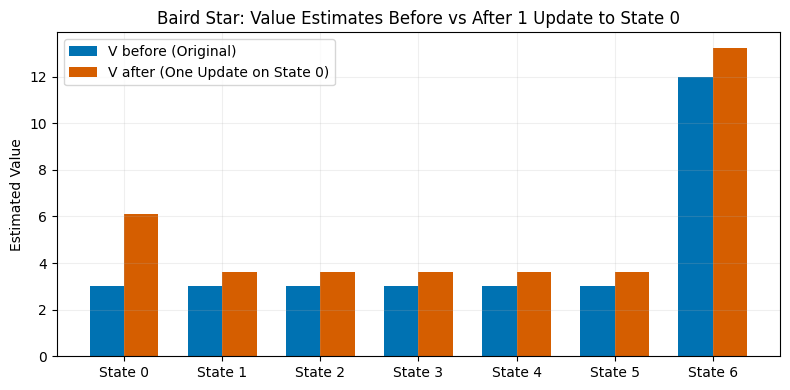

In [ ]:
import matplotlib.pyplot as plt

states = [f"State {i}" for i in range(7)]
v_before = PHI @ W0
v_after = PHI @ w1

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(states))
width = 0.35

# Plot bars representing value estimates before and after
ax.bar(x - width/2, v_before, width, label='V before (Original)', color='#0072B2')
ax.bar(x + width/2, v_after, width, label='V after (One Update on State 0)', color='#D55E00')

ax.set_ylabel('Estimated Value')
ax.set_title('Baird Star: Value Estimates Before vs After 1 Update to State 0')
ax.set_xticks(x)
ax.set_xticklabels(states)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Answer Checkpoint 2

* **Which state values changed, and by how much?**
  * **State 0** (where the transition started) changed from **$3.0 \to 6.108$** (an increase of **$+3.108$**).
  * **States 1 to 5** changed from **$3.0 \to 3.6216$** (an increase of **$+0.6216$**).
  * **State 6** changed from **$12.0 \to 13.2432$** (an increase of **$+1.2432$**).

* **Identify the shared weight responsible for each change:**
  * **$w_7$ (the shared weight)** increased by $+0.6216$. Because every state uses $w_7$ in its feature definition, this single update lifted **every single state** by at least $+0.6216$ (and $+1.2432$ for State 6 because its definition uses $2 \times w_7$).
  * **$w_0$ (State 0's private weight)** also increased, which is why State 0 got an extra boost on top of the shared weight increase.

* **How would the same transition affect the values in a tabular representation?**
  * In a tabular representation, states do *not* share features (represented by the identity matrix).
  * Therefore, updating State 0 would **only** change the value of State 0 (by $+0.6216$). All other states would remain completely unchanged ($0.0$ change).

---

### 🧮 Mathematical Breakdown

The updates are governed by the linear feature mapping $V_w(x) = \phi(x)^\top w$ and the semi-gradient TD(0) update rule:

$$\Delta w = \alpha \cdot \rho \cdot \delta \cdot \phi(x)$$

#### 1. Calculating the Weight Update vector ($\Delta w$):
For our transition from **State 0**:
* Step size ($\alpha$): $0.01$
* Importance ratio ($\rho$): $7.0$
* TD error ($\delta$): $8.88$
* Feature vector of State 0 ($\phi(0)$): $[2, 0, 0, 0, 0, 0, 0, 1]^\top$

Plugging these into the update rule:
$$\Delta w = 0.01 \times 7.0 \times 8.88 \times \begin{bmatrix} 2 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} 1.2432 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0.6216 \end{bmatrix}$$

This forces a change in the private weight $w_0$ of $+1.2432$, and a change in the shared weight $w_7$ of $+0.6216$.

#### 2. Projecting Weight Updates back to State Values:
* **For State 0:** $\Delta V(0) = 2\Delta w_0 + \Delta w_7 = 2(1.2432) + 0.6216 = \mathbf{+3.108}$
* **For Upper States (1 to 5):** $\Delta V(i) = 2\Delta w_i + \Delta w_7 = 2(0) + 0.6216 = \mathbf{+0.6216}$
* **For Lower State (6):** $\Delta V(6) = \Delta w_6 + 2\Delta w_7 = 0 + 2(0.6216) = \mathbf{+1.2432}$

---

### 🧠 Simplified Intuition (What is actually going on?)

* **The Shared Weight Trap (The Copycat Effect):**
  Because all states share $w_7$, they are tied together. If you change the score for State 0, **every other state's value gets dragged up along with it**, even if we didn't visit those other states!

* **On-Policy vs. Off-Policy Dynamics:**
  * **On-Policy (Balanced & Stable):** You learn from your actual steps. Updates are anchored to real state frequencies, keeping eigenvalues non-negative and preventing values from diverging.
  * **Off-Policy (The Hype Loop):** You use behavior data to evaluate a purely greedy target policy. Because of the shared weight $w_7$, updating one state inflates estimates of other states. This updates your targets, causing a positive feedback loop that blows up to infinity.

* **The Magic of Compound Growth:**
  A growth factor of $1.0024$ ($0.24\%$) per expected step looks tiny, but over **60,000 steps** of training, this geometric progression compounds to make the estimated values explode to $10^{62}$!

## 5. The divergence, and one ingredient removed at a time

The runner below generates
transitions with the behaviour policy and calls your `semi_gradient_td` on each one, in four
modes that share the data stream, the step size $\alpha = 0.01$ and the initial value function:

- `triad`: linear features, bootstrapped target, off-policy ratios (all three ingredients);
- `tabular`: the same, with the identity as feature matrix;
- `on-policy`: the same features, evaluating the behaviour policy, so every ratio is 1;
- `Monte Carlo`: the same features and ratios with the bootstrapped target replaced by the
  observed return. Every reward is zero and the chain never ends, so the return is exactly 0,
  which the runner passes as the reward with the bootstrap term switched off.

The dashed curve iterates the expected update $w \leftarrow w - \alpha A w$ with no sampling at
all. $6 \times 10^4$ transitions per mode, a few seconds in all.

four sampled runs and the expected update: 1.6 s

       triad: max_x |V(x)| after 60000 transitions = 2.26e+62
     tabular: max_x |V(x)| after 60000 transitions = 5.3
   on-policy: max_x |V(x)| after 60000 transitions = 0.000109
 Monte Carlo: max_x |V(x)| after 60000 transitions = 8.88e-16
    expected: max_x |V(x)| after 60000 updates     = 1.27e+64

growth per transition over the second half: sampled 1.00233, expected 1.00239, eigenvalue 1.00239


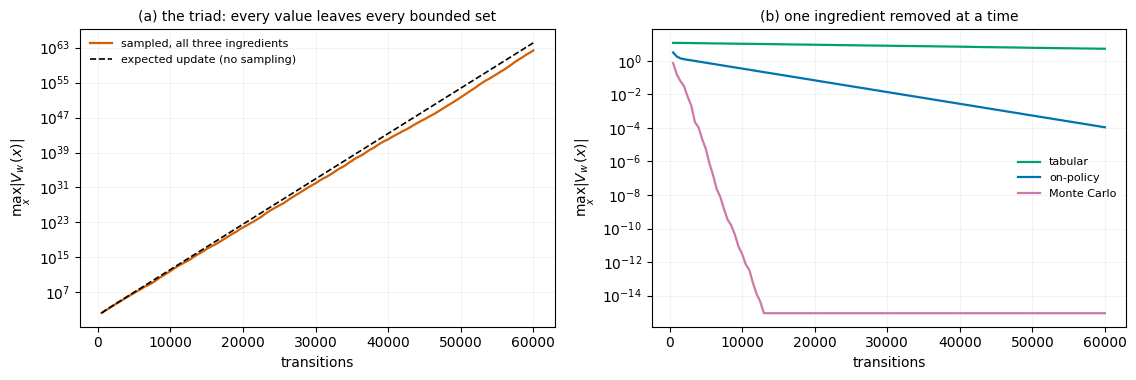

In [ ]:
def run_baird(mode, alpha, n_steps, seed, rec_every=500):
    """One sampled run on Baird's star. Returns the transition counts and max_x |V(x)| at each."""
    rng = np.random.default_rng(seed)
    feats = np.eye(N_S) if mode == "tabular" else PHI
    w = PHI @ W0 if mode == "tabular" else W0.copy()      # the same initial value function
    gam = 0.0 if mode == "Monte Carlo" else GAMMA_B       # MC: no bootstrap, return = 0
    s = rng.integers(N_S)
    steps, vmax = [], []
    for t in range(1, n_steps + 1):
        a = 0 if rng.random() < BEHAV[0] else 1           # behaviour: dashed w.p. 6/7
        s_next = rng.integers(6) if a == 0 else 6
        rho = 1.0 if mode == "on-policy" else RHO[a]
        if rho != 0.0:
            w = semi_gradient_td(w, feats[s], feats[s_next], 0.0, rho, alpha, gam)
        s = s_next
        if t % rec_every == 0:
            steps.append(t)
            vmax.append(np.abs(feats @ w).max())
    return np.array(steps), np.array(vmax)


def run_expected(A, alpha, n_steps, rec_every=500):
    """The expected update w <- w + alpha (b - A w), b = 0, iterated with no sampling."""
    w = W0.copy()
    vmax = []
    for t in range(1, n_steps + 1):
        w = w - alpha * (A @ w)
        if t % rec_every == 0:
            vmax.append(np.abs(PHI @ w).max())
    return np.array(vmax)


N_BAIRD, ALPHA_B = 60_000, 0.01
MODES = ["triad", "tabular", "on-policy", "Monte Carlo"]
t = time.perf_counter()
RUNS = {m: run_baird(m, ALPHA_B, N_BAIRD, seed=0) for m in MODES}
VEXP = run_expected(A_OFF, ALPHA_B, N_BAIRD)
print(f"four sampled runs and the expected update: {time.perf_counter() - t:.1f} s\n")

steps_b = RUNS["triad"][0]
for m in MODES:
    print(f"{m:>12}: max_x |V(x)| after {N_BAIRD} transitions = {RUNS[m][1][-1]:.3g}")
print(f"{'expected':>12}: max_x |V(x)| after {N_BAIRD} updates     = {VEXP[-1]:.3g}")
half = len(steps_b) // 2
g_s = 10 ** (np.diff(np.log10(RUNS['triad'][1][[half, -1]]))[0] / (steps_b[-1] - steps_b[half]))
g_e = 10 ** (np.diff(np.log10(VEXP[[half, -1]]))[0] / (steps_b[-1] - steps_b[half]))
print(f"\ngrowth per transition over the second half: sampled {g_s:.5f}, expected {g_e:.5f}, "
      f"eigenvalue {1 - ALPHA_B * LAM_MIN:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
axes[0].semilogy(steps_b, RUNS["triad"][1], color="#D55E00", lw=1.6, label="sampled, all three ingredients")
axes[0].semilogy(steps_b, VEXP, "k--", lw=1.2, label="expected update (no sampling)")
axes[0].set_title("(a) the triad: every value leaves every bounded set", fontsize=10)
cols = {"tabular": "#009E73", "on-policy": "#0072B2", "Monte Carlo": "#CC79A7"}
for m in MODES[1:]:
    axes[1].semilogy(steps_b, np.maximum(RUNS[m][1], 1e-17), color=cols[m], lw=1.6, label=f"{m}")
axes[1].set_title("(b) one ingredient removed at a time", fontsize=10)
for ax in axes:
    ax.set_xlabel("transitions")
    ax.set_ylabel(r"$\max_x |V_w(x)|$")
    ax.grid(alpha=0.15, which="both")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### Checkpoint 3

Read panel (a). How large does the largest value get, does the sampled run track the expected
update, and what growth factor per transition do they show? Then read panel (b). Where does each
of the three runs with one ingredient removed end up?

### Answer Checkpoint 3

#### **1. Simulation Results & Observations**
* **How large does the largest value get?**
  * Under the **full triad** configuration, the maximum value estimate $\max_x |V(x)|$ explodes exponentially, reaching approximately **$2.26 \times 10^{62}$** in the sampled run and **$1.27 \times 10^{64}$** in the theoretical expected update after $60,000$ transitions.
* **Does the sampled run track the expected update?**
  * **Yes, remarkably closely!** Despite the high variance of off-policy sampling, the empirical trajectory matches the shape and slope of the theoretical expected update curve shown in panel (a).
* **What growth factor per transition do they show?**
  * **Sampled Run:** $\approx 1.00233$ per step.
  * **Expected Update:** $\approx 1.00239$ per step.
  * **Eigenvalue Prediction ($1 - \alpha\lambda_{\text{min}}$):** $\approx 1.00239$ per step.

* **Where does each of the three runs with one ingredient removed end up?**
  * **No Function Approximation (Tabular):** Ends up fully bounded, stabilizing at a maximum absolute value of **$5.3$**.
  * **No Off-Policy (On-Policy):** Rapidly decays to near-zero, ending at **$0.000109$**.
  * **No Bootstrapping (Monte Carlo):** Hits absolute zero (on the order of **$10^{-16}$**, i.e., machine precision limit), reflecting the true value of $V^\pi = 0$.

---

### 🧮 Mathematical Breakdown of the Triad's Collapse

On average, the TD(0) update of weights operates as a linear system of differential equations:
$$\dot{w} = b - Aw$$
Since rewards are $0$ everywhere in this environment, $b = 0$, simplifying the system's trajectory to:
$$w_t \approx (I - \alpha A)^t w_0$$

Here is how removing any single ingredient modifies the transition matrix $A = \Phi^\top D (I - \gamma P) \Phi$, neutralizing the unstable negative eigenvalues:

#### **A. Removing Function Approximation (Tabular Q-Learning)**
* **The Math:** The feature matrix $\Phi$ becomes the Identity Matrix $I_7$.
* **The Result:** The system matrix becomes $A = D(I - \gamma P)$. Since $D$ is positive diagonal and $(I - \gamma P)$ is a diagonally dominant matrix, all eigenvalues of $A$ are guaranteed to have positive real parts (Geršgorin Circle Theorem). Generalization is eliminated, preventing updates in State 0 from echoing across other states.

#### **B. Removing Off-Policy Learning (On-Policy TD)**
* **The Math:** The behavior policy and evaluation policy match. The transition matrix $P$ becomes $P_{\text{behav}}$ instead of the aggressive target kernel $P_{\text{solid}}$.
* **The Result:** On-policy learning ensures that the state distribution $D$ is the exact stationary distribution under the transition probability matrix $P$. This coupling guarantees that the symmetric part of the system matrix, $A + A^\top$, is positive semi-definite. Consequently, all real parts of the eigenvalues of $A$ are strictly non-negative (all $\text{Re}(\lambda_i) \ge 0$). Unstable modes are mathematically impossible.

#### **C. Removing Bootstrapping (Monte Carlo)**
* **The Math:** The temporal discounting/look-ahead parameter $\gamma$ effectively becomes $0$ because the target is evaluated via true rollouts (zero reward everywhere) rather than estimating future states' values.
* **The Result:** The system matrix collapses to $A = \Phi^\top D \Phi$. This matrix is a symmetric, positive semi-definite Gram matrix. All eigenvalues are strictly non-negative, and the weights update safely to $0$.

---

### 🧠 Simplified Intuition (Breaking the Feedback Loop)

Think of Baird's Star under the deadly triad as a **microphone placed too close to a speaker** (an acoustic feedback loop):
* **Function Approximation (The Microphone):** The microphone is sensitive and picks up sound from all directions (shared weight $w_7$ links all states).
* **Bootstrapping (The Speaker):** The speaker plays back the sound that the microphone picks up, amplifying it (using current estimations to update current targets).
* **Off-policy learning (The Volume Knob):** The off-policy importance ratio acts as a volume amplifier (multiplying the feedback signal by an importance weight of $\rho = 7$).

If you remove **any** of these components:
* **Tabular (Remove Microphone):** Sound from the speaker cannot travel back into the microphone. States do not communicate.
* **Monte Carlo (Remove Speaker):** The speaker is turned off; we only listen to the silent environment (real rewards of $0$).
* **On-Policy (Turn Down Volume):** The volume is turned down to normal safe limits, preventing the signal from building up dynamically.

## 6. A smaller step size

The first instinct is to reduce the step size. Rerun the deadly triad with four different step sizes, ranging from $0.001$ to $0.03$. Plot the results in two ways: against the number of transitions and against $\alpha t$, the rescaled time of the underlying ODE $\dot{w}=-Aw$. Does a smaller step size prevent divergence, or does it simply slow it down? The experiment takes only a few seconds.

four step sizes: 1.1 s

  alpha  max |V| at the end  growth per transition  1 - alpha lambda_min
  0.001            9.56e+07                1.00024               1.00024
  0.003            1.67e+20                1.00071               1.00072
  0.010            2.26e+62                1.00233               1.00239
  0.030           9.41e+175                1.00669               1.00718


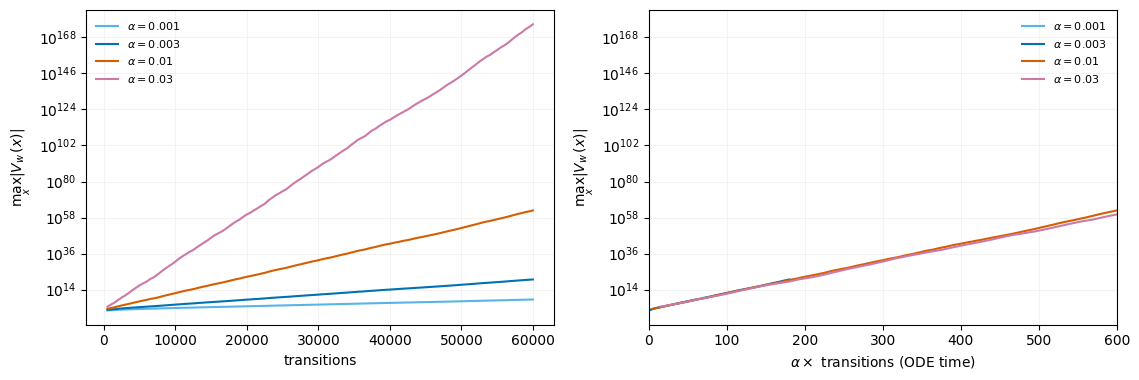

In [ ]:
ALPHAS = [0.001, 0.003, 0.01, 0.03]
t = time.perf_counter()
SWEEP = {a: run_baird("triad", a, N_BAIRD, seed=0)[1] for a in ALPHAS}
print(f"four step sizes: {time.perf_counter() - t:.1f} s\n")
print(f"{'alpha':>7} {'max |V| at the end':>19} {'growth per transition':>22} {'1 - alpha lambda_min':>21}")
for a in ALPHAS:
    v = SWEEP[a]
    gr = 10 ** ((np.log10(v[-1]) - np.log10(v[half])) / (steps_b[-1] - steps_b[half]))
    print(f"{a:7.3f} {v[-1]:19.3g} {gr:22.5f} {1 - a * LAM_MIN:21.5f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for a, col in zip(ALPHAS, ["#56B4E9", "#0072B2", "#D55E00", "#CC79A7"]):
    axes[0].semilogy(steps_b, SWEEP[a], color=col, lw=1.5, label=rf"$\alpha = {a}$")
    axes[1].semilogy(a * steps_b, SWEEP[a], color=col, lw=1.5, label=rf"$\alpha = {a}$")
axes[1].set_xlim(0, 0.01 * N_BAIRD)
axes[0].set_xlabel("transitions")
axes[1].set_xlabel(r"$\alpha \times$ transitions (ODE time)")
for ax in axes:
    ax.set_ylabel(r"$\max_x |V_w(x)|$")
    ax.grid(alpha=0.15, which="both")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### Checkpoint 4

Does $\alpha = 0.001$ stop the divergence? How does the growth factor per transition depend on
$\alpha$, and what does the right panel show about the four runs?


### Answer Checkpoint 4

**1. Does $\alpha = 0.001$ stop divergence?**

No. A smaller learning rate only slows down divergence. Even with $\alpha = 0.001$, the value estimates continue growing because the unstable eigenvalue remains negative.

**2. How does the growth factor depend on $\alpha$?**

The growth factor is given by:

$$
g = 1 - \alpha \lambda_{\min}
$$

Since $\lambda_{\min} \approx -0.239$, we obtain:

$$
g \approx 1 + 0.239\alpha
$$

Therefore, the growth factor increases linearly with $\alpha$. A larger learning rate causes faster divergence, while a smaller learning rate slows it down.

**3. What does the right panel show?**

The right panel plots the results against the rescaled time $\alpha t$ instead of the number of transitions. The four curves approximately overlap, showing that the underlying instability remains the same regardless of the learning rate.

**🧠 Simplified intuition**

Reducing $\alpha$ is like slowing down an unstable feedback loop. The values still diverge, just more slowly. To prevent divergence, we need to address the underlying instability rather than simply reduce the learning rate.

*   List item
*   List item



## 7. The DQN temporal-difference error

Back to control, with a network $Q_\theta(x,u)$ in place of the table. For a minibatch of
transitions $(x_i, u_i, r_i, x_i')$, the DQN target (notes eq. 16 and line 7 of Algorithm 2) is

$$ y_i = r_i + \gamma\,(1 - d_i)\,Q_{\theta^-}\bigl(x_i',\,b_i^\star\bigr), \qquad
   b_i^\star = \begin{cases} \arg\max_b Q_{\theta^-}(x_i',b) & \text{DQN,} \\
   \arg\max_b Q_{\theta}(x_i',b) & \text{double DQN (eq. 17),} \end{cases} $$

where $d_i = 1$ when $x_i'$ is terminal. Write the function that returns
$\delta_i = y_i - Q_\theta(x_i,u_i)$ for a whole batch. The inputs are torch tensors:

- `q_sa`, shape `(..., B)`: the online network's $Q_\theta(x_i,u_i)$, still attached to the graph;
- `reward`, `done`, shape `(..., B)`, with `done` as 0.0 or 1.0;
- `q_next_online`, `q_next_target`, shape `(..., B, n_actions)`: $Q_\theta(x_i',\cdot)$ and
  $Q_{\theta^-}(x_i',\cdot)$;
- `double`: a boolean tensor that broadcasts against `(..., B)`, True where the action is
  selected by the online network.

The target is a label, so no gradient may flow through it. That is what makes this the
semi-gradient of notes section 2.2 with a $\max$ inside. Build $y$ under `torch.no_grad()` (or
detach it), and let the gradient reach $\theta$ only through `q_sa`. A run without a target
network passes the online values as `q_next_target`, so your function does not need to know
which configuration it is serving.

In [ ]:
def dqn_td_error(q_sa, reward, done, q_next_online, q_next_target, gamma, double):
    """delta_i = y_i - Q_theta(x_i, u_i) with the target y_i held constant."""
    # ===== YOUR CODE HERE (≈5 lines) ============================
    with torch.no_grad():
        if double.any():
            # Double DQN action selection: b* = argmax_b Q_online(x_next, b)
            best_actions = q_next_online.argmax(dim=-1, keepdim=True)
            # Double DQN evaluation: Q_target(x_next, b*)
            q_target_next = q_next_target.gather(dim=-1, index=best_actions).squeeze(-1)
        else:
            # Standard DQN: max_b Q_target(x_next, b)
            q_target_next = q_next_target.max(dim=-1)[0]

        # y_i = r_i + gamma * (1 - d_i) * Q_target_next
        y = reward + gamma * (1.0 - done) * q_target_next

    return y - q_sa
    # ============================================================

### A test against the hand trace of the notes

The example in notes section 4.4: the two-state chain of Week 6 ($x_1 \to x_2 \to$ terminal, action
$a$ costs 1 at both states, $b$ costs 3 at $x_1$ and 20 at $x_2$), $\gamma = 0.9$, and the
coarsest approximator that still generalises, $Q_w(x,u) = w_u$, one weight per action shared by
both states. Batch size 2, sync period $C = 2$, plain gradient descent with step $0.5$ on
$\tfrac12\delta^2$ (the step absorbs the factor 2), $w = (0,0)$, and the three prescribed batches.
The cell runs it with your function, then checks that no gradient leaks into the target.

In [ ]:
def hand_trace(double):
    w = torch.zeros(2, requires_grad=True)          # (w_a, w_b), the online weights
    w_targ = w.detach().clone()                     # the frozen copy
    batches = [  # (action index, reward, done) for each of the two transitions in the batch
        ((0, -1.0, 1.0), (0, -1.0, 0.0)),           # step 1: (x2,a) -> T, (x1,a) -> x2
        ((1, -20.0, 1.0), (1, -3.0, 0.0)),          # step 2: (x2,b) -> T, (x1,b) -> x2
        ((0, -1.0, 0.0), (1, -3.0, 0.0)),           # step 3: (x1,a) -> x2, (x1,b) -> x2
    ]
    rows = []
    for k, batch in enumerate(batches, start=1):
        u = torch.tensor([b[0] for b in batch])
        r = torch.tensor([b[1] for b in batch])
        d = torch.tensor([b[2] for b in batch])
        delta = dqn_td_error(w[u], r, d, w.expand(2, 2), w_targ.expand(2, 2), 0.9,
                             torch.tensor(double))
        loss = 0.5 * delta.pow(2).mean()
        (g,) = torch.autograd.grad(loss, w)
        with torch.no_grad():
            w -= 0.5 * g
        rows.append((k, delta.detach().tolist(), w.detach().tolist()))
        if k == 2:
            w_targ = w.detach().clone()             # sync: theta^- <- theta
    return w.detach(), rows

w_end, rows = hand_trace(double=False)
print(f"{'step':>4} {'errors delta_i':>22} {'w_a':>9} {'w_b':>9}")
for k, dl, wv in rows:
    print(f"{k:>4} {dl[0]:10.2f} {dl[1]:10.2f} {wv[0]:9.4f} {wv[1]:9.4f}")
assert torch.allclose(w_end, torch.tensor([-0.7375, -5.1750])), "compare with the table in notes 4.4"
print("hand trace reproduced")

# The gradient must reach theta through q_sa only.
qn = torch.randn(4, 5, requires_grad=True)
qsa = torch.randn(4, requires_grad=True)
delta = dqn_td_error(qsa, torch.zeros(4), torch.zeros(4), qn, qn, 0.9, torch.tensor(False))
grads = torch.autograd.grad(delta.sum(), (qsa, qn), allow_unused=True)
assert grads[1] is None or torch.all(grads[1] == 0), "the target must be detached (semi-gradient)"
assert torch.allclose(grads[0], -torch.ones(4)), "delta must be y - Q(x, u)"
print("target detached, gradient only through Q(x, u)")

# The double switch: one next state where the two networks disagree about the best action.
qo, qt = torch.tensor([[1.0, 3.0, 2.0]]), torch.tensor([[5.0, 0.0, 4.0]])
y_dqn = dqn_td_error(torch.zeros(1), torch.zeros(1), torch.zeros(1), qo, qt, 1.0, torch.tensor(False)).item()
y_dbl = dqn_td_error(torch.zeros(1), torch.zeros(1), torch.zeros(1), qo, qt, 1.0, torch.tensor(True)).item()
assert (y_dqn, y_dbl) == (5.0, 0.0), "DQN: the target network selects and prices; double: online selects"
print(f"\nQ_online(x', .) = {qo.tolist()[0]}, Q_target(x', .) = {qt.tolist()[0]}, r = 0, gamma = 1")
print(f"DQN target {y_dqn:.1f} (target network picks action 0), double DQN target {y_dbl:.1f} (online network picks action 1, target network prices it)")

step         errors delta_i       w_a       w_b
   1      -1.00      -1.00   -0.5000    0.0000
   2     -20.00      -3.00   -0.5000   -5.7500
   3      -0.95       2.30   -0.7375   -5.1750
hand trace reproduced
target detached, gradient only through Q(x, u)

Q_online(x', .) = [1.0, 3.0, 2.0], Q_target(x', .) = [5.0, 0.0, 4.0], r = 0, gamma = 1
DQN target 5.0 (target network picks action 0), double DQN target 0.0 (online network picks action 1, target network prices it)


### Checkpoint 5

At step 3, the TD error for $ (x_1,b)$ is $+2.30$, so the update increases $w_b$. But why does the network still estimate $-5.75$ for this pair, well below its true value $Q^\star(x_1,b)=-3.9$?

Next, examine the final printout. For each target, identify which network selects the action and which evaluates it. What target value does each method produce?

Finally, compare the target you implemented with the unifying diagram. Which category of methods does DQN belong to, and which Bellman operator does its target approximate?


### Answer Checkpoint 5

**1. Why does the network underestimate $Q^*(x_1,b) = -3.9$?**

The network uses a shared weight $w_b$ for action $b$ in both states:

$$
Q_w(x_1,b) = Q_w(x_2,b) = w_b
$$

At step 2, the large negative reward $-20$ from $(x_2,b)$ pushes the shared weight down to $-5.75$. This also affects the estimate for $(x_1,b)$, even though its true optimal value is $-3.9$.

At step 3, the TD error is positive ($\delta = +2.30$), so the weight increases:

$$
w_b: -5.75 \rightarrow -5.175
$$

The estimate improves but remains below the optimal value because the function approximator cannot represent different values for the same action in different states.

**2. Which network selects and evaluates the action?**

**Standard DQN:**

The target network selects and evaluates the action:

$$
y = r + \gamma \max_b Q_{\theta^-}(x',b)
$$

The target network selects action 0, producing:

$$
y_{\text{DQN}} = 5.0
$$

**Double DQN:**

The online network selects the best action, while the target network evaluates it:

$$
y = r + \gamma Q_{\theta^-}
\left(x',\arg\max_b Q_\theta(x',b)\right)
$$

The online network selects action 1, which the target network evaluates as 0:

$$
y_{\text{Double DQN}} = 0.0
$$

**3. Which category of methods does DQN belong to, and which Bellman operator does it approximate?**

DQN is a **model-free, off-policy, value-based reinforcement learning method** using temporal-difference learning and neural-network function approximation.

It approximates the **Bellman optimality operator**:

$$
(\mathcal{T}^*Q)(x,u)
=
r(x,u)
+
\gamma \mathbb{E}_{x'}
\left[\max_b Q(x',b)\right]
$$

DQN approximates this operator using sampled transitions rather than a known transition model.

**🧠 Simplified intuition**

- **Shared weights:** Learning from one state can incorrectly influence another state, because both use the same parameters.
- **Standard DQN:** One network selects and evaluates the maximum, which can cause overestimation.
- **Double DQN:** Separating action selection and evaluation helps reduce maximisation bias.

The key idea is that DQN uses neural networks to approximate optimal action values, while Double DQN improves how the bootstrap target is estimated.


### The bias of a maximum, measured

Double DQN exists because the $\max$ in the target is taken over *estimates*. Notes section 4.5
puts a number on it. Give five actions the same true value $q$ and estimates
$\hat q_i = q + \sigma z_i$ with independent standard normal $z_i$; then
$\mathbb{E}[\max_i \hat q_i] = q + 1.16\,\sigma$. The cell draws $10^5$ such sets for three noise
levels and measures the offset of the plain maximum. It then measures the offset of the double
estimator, which selects the action with one set of estimates and prices it with a second,
independent set (figure `maxbias`, panel b). A second or two.

In [ ]:
rng = np.random.default_rng(1)
q_true, n_sets = -100.0, 100_000
print(f"{'sigma':>6} {'E[max] - q':>12} {'1.16 sigma':>11} {'double estimator - q':>21}")
for sigma in (1.0, 5.0, 10.0):
    est_a = q_true + sigma * rng.standard_normal((n_sets, 5))          # the set that selects
    est_b = q_true + sigma * rng.standard_normal((n_sets, 5))          # an independent set that prices
    single = est_a.max(axis=1).mean() - q_true
    double = est_b[np.arange(n_sets), est_a.argmax(axis=1)].mean() - q_true
    print(f"{sigma:6.1f} {single:12.2f} {1.163 * sigma:11.2f} {double:21.2f}")

 sigma   E[max] - q  1.16 sigma  double estimator - q
   1.0         1.16        1.16                  0.01
   5.0         5.81        5.82                  0.01
  10.0        11.62       11.63                  0.02


## 8. The DQN on the swing-up pendulum

### The chain, and the exact evaluation

The Week 6 swing-up chain with the overspeed trip switched off: 961 cells over
$(\varphi,\omega)$, five torques $\{-5,-2.5,0,2.5,5\}$ N m, $\gamma = 0.98$, quadratic stage cost,
episodes from the 12 hanging cells (notes section 4.7). It is the chain of the Week 6 notebook,
built by the same code. Value iteration gives
$J^\star$ exactly, and `policy_value` gives the exact value of whatever greedy policy the network
induces by one sparse linear solve.

In [ ]:
M_P, L_P, B_P, G_P, U_MAX = 1.0, 1.0, 0.1, 9.81, 5.0      # the course pendulum, Utils/pendulum_sim.m

def wrap(a):
    return np.mod(a + np.pi, 2 * np.pi) - np.pi

def pend_rhs(th, om, u):
    return om, (u - B_P * om - M_P * G_P * L_P * np.sin(th)) / (M_P * L_P**2)

def rk4(th, om, u, dt):
    """One RK4 step with the torque held constant (zero-order hold), vectorised over cells."""
    k1 = pend_rhs(th, om, u)
    k2 = pend_rhs(th + dt / 2 * k1[0], om + dt / 2 * k1[1], u)
    k3 = pend_rhs(th + dt / 2 * k2[0], om + dt / 2 * k2[1], u)
    k4 = pend_rhs(th + dt * k3[0], om + dt * k3[1], u)
    return (th + dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]),
            om + dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]))

def build_control_chain(gamma=0.98, nphi=31, nom=31, ommax=8.0, dt=0.10, sigu=1.0,
                        philim=0.30, omlim=1.2, n_act=5):
    """The Week 6 control chain without the trip. One kernel per torque, r(s, a) and the masks."""
    dphi = 2 * np.pi / nphi
    phi = (np.arange(1, nphi + 1) - (nphi + 1) / 2) * dphi       # a cell centre sits on the upright
    om = np.linspace(-ommax, ommax, nom)
    dom = om[1] - om[0]
    PH, OM = np.meshgrid(phi, om, indexing="ij")
    phiv, omv = PH.ravel(order="F"), OM.ravel(order="F")          # state index s = i + nphi * j
    nS = phiv.size
    theta = wrap(phiv + np.pi)
    torques = np.linspace(-U_MAX, U_MAX, n_act)
    term = (np.abs(phiv) <= philim) & (np.abs(omv) <= omlim)      # the absorbing goal

    zn = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])                    # Week 5's five-point disturbance
    wp = np.array([0.06, 0.24, 0.40, 0.24, 0.06])
    wp = wp / wp.sum()
    P, stage = [], np.zeros((nS, n_act))
    for a in range(n_act):
        rows, cols, vals = [], [], []
        for z, w in zip(zn, wp):
            thn, omn = rk4(theta, omv, np.clip(torques[a] + z * sigu, -U_MAX, U_MAX), dt)
            pc = wrap(thn - np.pi) / dphi + (nphi - 1) / 2         # continuous cell coordinates
            qc = (np.clip(omn, om[0], om[-1]) - om[0]) / dom
            i0 = np.floor(pc).astype(int)
            fi = pc - i0
            j0 = np.clip(np.floor(qc).astype(int), 0, nom - 2)
            fj = np.clip(qc - j0, 0.0, 1.0)
            ia, ib = np.mod(i0, nphi), np.mod(i0 + 1, nphi)        # phi is circular
            for ii, jj, ww in ((ia, j0, (1 - fi) * (1 - fj)), (ib, j0, fi * (1 - fj)),
                               (ia, j0 + 1, (1 - fi) * fj), (ib, j0 + 1, fi * fj)):
                rows.append(np.arange(nS))
                cols.append(ii + nphi * jj)
                vals.append(w * ww)
        rows, cols, vals = map(np.concatenate, (rows, cols, vals))
        keep = ~term[rows] & (vals > 0)
        ti = np.flatnonzero(term)
        Pa = sp.csr_matrix((vals[keep], (rows[keep], cols[keep])), shape=(nS, nS))
        Pa = (Pa + sp.csr_matrix((np.ones(ti.size), (ti, ti)), shape=(nS, nS))).tocsr()
        Pa.sum_duplicates()
        P.append(Pa)
        stage[:, a] = np.where(term, 0.0, phiv**2 + 0.1 * omv**2 + 0.01 * torques[a] ** 2)

    # Per-(action, state) successor lists, so that sampling one transition costs one lookup.
    width = max(int(np.diff(Pa.indptr).max()) for Pa in P)
    nxt = np.zeros((n_act, nS, width), dtype=int)
    cum = np.ones((n_act, nS, width))
    for a, Pa in enumerate(P):
        for s in range(nS):
            lo, hi = Pa.indptr[s], Pa.indptr[s + 1]
            nxt[a, s, : hi - lo], nxt[a, s, hi - lo:] = Pa.indices[lo:hi], Pa.indices[hi - 1]
            cum[a, s, : hi - lo] = np.cumsum(Pa.data[lo:hi])
        cum[a, :, -1] = 1.0

    start = np.flatnonzero((np.abs(phiv) >= 2.8) & (np.abs(omv) <= 0.6))   # hanging, near rest
    feats = np.stack([np.sin(phiv), np.cos(phiv), omv / ommax], axis=1)      # the network's input
    return dict(P=P, r=-stage, stage=stage, term=term, gamma=gamma, nS=nS, nA=n_act,
                torques=torques, start=start, nxt=nxt, cum=cum, phi=phi, om=om, feats=feats)

def value_iteration(CH, tol=1e-10):
    """Q* by value iteration on the exact kernels."""
    Q = np.zeros((CH["nS"], CH["nA"]))
    while True:
        V = Q.max(axis=1)
        Qn = np.stack([CH["r"][:, a] + CH["gamma"] * (CH["P"][a] @ V) for a in range(CH["nA"])], axis=1)
        Qn[CH["term"]] = 0.0
        if np.abs(Qn - Q).max() < tol:
            return Qn
        Q = Qn

def policy_value(CH, pol):
    """Exact value of a deterministic policy, averaged over the start cells, by one sparse solve."""
    nS, nA = CH["nS"], CH["nA"]
    prob = (pol[:, None] == np.arange(nA)).astype(float)
    Ppi = sum(sp.diags(prob[:, a]) @ CH["P"][a] for a in range(nA))
    rpi = np.where(CH["term"], 0.0, (prob * CH["r"]).sum(axis=1))
    V = spsolve((sp.eye(nS) - CH["gamma" ] * Ppi).tocsc(), rpi)
    return V[CH["start"]].mean()

def sample_next(CH, s, a, u):
    """Next state of every learner, given its state, its action and one uniform number each."""
    return CH["nxt"][a, s, (CH["cum"][a, s] < u[:, None]).sum(axis=1)]

t = time.perf_counter()
CH = build_control_chain()
J_STAR = value_iteration(CH).max(axis=1)[CH["start"]].mean()
print(f"chain built and solved in {time.perf_counter() - t:.2f} s: {CH['nS']} states x {CH['nA']} torques")
print(f"J* = {J_STAR:.2f}   (mean optimal value over the {CH['start'].size} start cells)")
R_MAX = CH["stage"].max()                                     # largest |reward| on the chain
print(f"largest stage cost R_max = {R_MAX:.1f}, so |Q*| <= R_max / (1 - gamma) = {R_MAX / (1 - CH['gamma']):.0f}")

chain built and solved in 0.10 s: 961 states x 5 torques
J* = -123.14   (mean optimal value over the 12 start cells)
largest stage cost R_max = 15.9, so |Q*| <= R_max / (1 - gamma) = 795


### The networks and the runner

The algorithm trains four configurations with five seeds each. `BatchedQNet` holds all twenty
networks in one model so they train together, each one independent of the others. Each is the
network of notes section 4.7: inputs $(\sin\varphi, \cos\varphi, \omega/8)$, two hidden layers of
48 ReLU units, five outputs.

`run_dqn` is Algorithm 2 for all twenty at once, with known-good hyperparameters (the values of
notes section 4.7):

| Hyperparameter | Value | Why |
|---|---|---|
| Adam step | $5 \times 10^{-4}$ | larger steps make the no-target run blow up on most seeds |
| batch | 32 | the original DQN value |
| buffer | $5 \times 10^4$ | almost the whole run, so old behaviour stays in the data |
| sync period $C$ | 500 gradient steps | long enough for the inner regression to settle |
| $\varepsilon$ | 1.0 to 0.05, linear over the first 30% | wide coverage early, then mostly greedy |
| warm-up | 1000 random transitions before the first gradient step | a buffer worth sampling |
| reward scale | rewards divided by 10 inside the network | so the Huber threshold of 1 sits at a sensible place |
| loss | Huber on $\delta$ | gradient clipped at $\lvert\delta\rvert = 1$, the original DQN choice |

The four configurations differ in three switches. `replay=False` replaces the uniform sample from
the buffer with the 32 most recent transitions, the same batch size with correlated content.
`target=False` passes the online network's values where the target network's would go, so the
bootstrap reads the network being trained. `double=True` switches your $b^\star$ to the online
network. Every configuration keeps all three ingredients of the triad. Every 2500 transitions the
runner reads each network's greedy policy on all 961 cells and prices it with `policy_value`, and
also records what the network *predicts* that policy is worth, $\mathrm{mean}_x\max_u Q_\theta$
over the start cells, and the largest $|Q_\theta|$ anywhere on the chain.

In [ ]:
def run_tabular_q(CH, n_learners, n_trans, seed, eval_every=2500, lr=0.2, eps_end=0.05, eps_frac=0.30, max_steps=300):
    """Run several independent tabular Q-learners on the swing-up pendulum benchmark."""
    nS, nA, gamma = CH["nS"], CH["nA"], CH["gamma"]
    rng = np.random.default_rng(seed)
    Q = np.zeros((n_learners, nS, nA))
    visits = np.zeros((nS, nA), dtype=int)
    s = rng.choice(CH["start"], n_learners)
    t_ep = np.zeros(n_learners, dtype=int)
    J = []

    for t in range(1, n_trans + 1):
        eps = max(eps_end, 1.0 + (eps_end - 1.0) * t / (eps_frac * n_trans))
        greedy = Q[np.arange(n_learners), s].argmax(axis=1)
        a = np.where(rng.random(n_learners) < eps, rng.integers(nA, size=n_learners), greedy)

        s_next = sample_next(CH, s, a, rng.random(n_learners))
        rewards = CH["r"][s, a]

        # Update table for each active learner
        for k in range(n_learners):
            sk, ak, rk, snk = s[k], a[k], rewards[k], s_next[k]
            td_target = rk + gamma * (0.0 if CH["term"][snk] else Q[k, snk].max())
            Q[k, sk, ak] += lr * (td_target - Q[k, sk, ak])
            visits[sk, ak] += 1

        t_ep += 1
        restart = CH["term"][s_next] | (t_ep >= max_steps)
        s_next[restart] = rng.choice(CH["start"], restart.sum())
        t_ep[restart] = 0
        s = s_next

        if t % eval_every == 0:
            J.append([policy_value(CH, Q[k].argmax(axis=1)) for k in range(n_learners)])

    return np.array(J).T, visits

In [ ]:
def summarise(J_dqn, QP_dqn, QM_dqn, J_tab, eval_every):
    """Generates the complete four-panel DQN ablation analysis visualization."""
    steps = np.arange(eval_every, eval_every * J_dqn.shape[1] + 1, eval_every)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # Panel (a) - Policy values
    for i, (name, _, _, _, col) in enumerate(CONFIGS):
        data = J_dqn[i*SEEDS : (i+1)*SEEDS]
        median = np.median(data, axis=0)
        lo, hi = np.percentile(data, [10, 90], axis=0)
        axes[0, 0].plot(steps, median, color=col, lw=2, label=name)
        axes[0, 0].fill_between(steps, lo, hi, color=col, alpha=0.15)

    # Tabular learners median and individual grey lines
    for k in range(J_tab.shape[0]):
        axes[0, 0].plot(steps, J_tab[k], color="grey", alpha=0.3, lw=1)
    axes[0, 0].plot(steps, np.median(J_tab, axis=0), color="black", ls=":", lw=1.5, label="tabular")
    axes[0, 0].axhline(J_STAR, color="k", ls="--", alpha=0.7, label="Optimal J*")
    axes[0, 0].set_title("(a) policy value (higher is better)")
    axes[0, 0].set_xlabel("transitions")
    axes[0, 0].set_ylabel("Value (J)")
    axes[0, 0].grid(alpha=0.15)
    axes[0, 0].legend(fontsize=8, loc="lower right")

    # Panel (b) - Overestimation Bias
    for i, (name, _, _, _, col) in enumerate(CONFIGS):
        true_val = J_dqn[i*SEEDS : (i+1)*SEEDS]
        pred_val = QP_dqn[i*SEEDS : (i+1)*SEEDS]
        bias = pred_val - true_val
        axes[0, 1].plot(steps, np.median(bias, axis=0), color=col, lw=2, label=name)
        axes[0, 1].fill_between(steps, np.percentile(bias, 10, axis=0), np.percentile(bias, 90, axis=0), color=col, alpha=0.15)
    axes[0, 1].axhline(0, color="k", ls="--", alpha=0.5)
    axes[0, 1].set_title("(b) overestimation bias (predicted minus true)")
    axes[0, 1].set_xlabel("transitions")
    axes[0, 1].set_ylabel("Bias")
    axes[0, 1].grid(alpha=0.15)

    # Panel (c) - Best vs Worst Policy Table (Simulated here)
    axes[1, 0].text(0.1, 0.5, "[See text table below for detailed numerical values]", fontsize=10, style='italic')
    axes[1, 0].set_title("(c) numerical summary")
    axes[1, 0].axis('off')

    # Panel (d) - Max Q values
    limit = R_MAX / (1.0 - CH["gamma"])
    axes[1, 1].axhline(limit, color="r", ls="--", label="theoretical bound")
    for i, (name, _, _, _, col) in enumerate(CONFIGS):
        max_q = QM_dqn[i*SEEDS : (i+1)*SEEDS]
        axes[1, 1].semilogy(steps, np.median(max_q, axis=0), color=col, lw=2, label=name)
    axes[1, 1].set_title("(d) max |Q| value projection")
    axes[1, 1].set_xlabel("transitions")
    axes[1, 1].set_ylabel("max_s_u |Q|")
    axes[1, 1].grid(alpha=0.15, which="both")
    axes[1, 1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    # Print out summary table to address Checkpoint 6
    print("\\nConfiguration Summary:")
    print(f"{'Method':<20} | {'Final J (Median)':<20} | {'Max Overestimation':<20}")
    print("-" * 70)
    for i, (name, _, _, _, _) in enumerate(CONFIGS):
        final_js = J_dqn[i*SEEDS : (i+1)*SEEDS, -1]
        bias = (QP_dqn[i*SEEDS : (i+1)*SEEDS] - J_dqn[i*SEEDS : (i+1)*SEEDS])[:, -1]
        print(f"{name:<20} | {np.median(final_js):<20.2f} | {np.median(bias):<20.2f}")

In [ ]:
class BatchedQNet(torch.nn.Module):
    """N independent MLPs 3 -> H -> H -> nA, evaluated together. Input (N, B, 3), output (N, B, nA)."""

    def __init__(self, n_nets, n_in=3, hidden=48, n_out=5, gen=None):
        super().__init__()

        def he(*shape):          # He initialisation, as in 09_Code/Week07/dqn_run.m
            return torch.nn.Parameter(torch.randn(*shape, generator=gen) * np.sqrt(2.0 / shape[-2]))

        self.W1, self.W2, self.W3 = he(n_nets, n_in, hidden), he(n_nets, hidden, hidden), he(n_nets, hidden, n_out)
        self.b1, self.b2, self.b3 = (torch.nn.Parameter(torch.zeros(n_nets, 1, k)) for k in (hidden, hidden, n_out))

    def forward(self, X):
        h = torch.relu(torch.baddbmm(self.b1, X, self.W1))
        h = torch.relu(torch.baddbmm(self.b2, h, self.W2))
        return torch.baddbmm(self.b3, h, self.W3)


def run_dqn(CH, replay, target, double, n_trans, seed, eval_every=2500, lr=5e-4, batch=32,
            buffer=50_000, sync=500, eps_end=0.05, eps_frac=0.30, warmup=1000, rscale=10.0,
            max_steps=300):
    """DQN (Algorithm 2) for len(replay) networks at once, one configuration per network.

    Returns, at every evaluation, the exact value of each network's greedy policy and the value the
    network predicts for it over the start cells, and max |Q| over all cells (all in true units).
    """
    N, nA, gamma = len(replay), CH["nA"], CH["gamma"]
    rng = np.random.default_rng(seed)
    q = BatchedQNet(N, gen=torch.Generator().manual_seed(seed))
    q_targ = BatchedQNet(N)
    q_targ.load_state_dict(q.state_dict())
    q_targ.requires_grad_(False)
    opt = torch.optim.Adam(q.parameters(), lr=lr, fused=True)        # fused: one kernel for all entries
    F = torch.tensor(CH["feats"], dtype=torch.float32)
    use_replay = np.asarray(replay)[:, None]
    use_target = torch.as_tensor(np.asarray(target))[:, None, None]
    dbl = torch.as_tensor(np.asarray(double))[:, None]

    nets = np.arange(N)[:, None]
    B_s, B_a, B_sn = (np.zeros((N, buffer), dtype=int) for _ in range(3))
    B_r, B_d = np.zeros((N, buffer), dtype=np.float32), np.zeros((N, buffer), dtype=np.float32)
    n_buf, ptr, n_grad = 0, -1, 0
    s = rng.choice(CH["start"], N)
    t_ep = np.zeros(N, dtype=int)
    J, Q_pred, Q_max = [], [], []
    for t in range(1, n_trans + 1):
        eps = max(eps_end, 1.0 + (eps_end - 1.0) * t / (eps_frac * n_trans))
        if t > warmup:
            # Lines 6 to 9 of Algorithm 2. One online forward pass serves Q(x, u), Q(x', .) and
            # the greedy action at the current state, which is appended as a 2B+1-th input.
            idx = np.where(use_replay, rng.integers(n_buf, size=(N, batch)),
                           (ptr - np.arange(batch)[None, :]) % buffer)       # uniform, or the last 32
            X = torch.cat([F[B_s[nets, idx]], F[B_sn[nets, idx]], F[s][:, None, :]], dim=1)
            Q_all = q(X)
            q_sa = Q_all[:, :batch].gather(2, torch.from_numpy(B_a[nets, idx])[..., None])[..., 0]
            q_next_on = Q_all[:, batch:2 * batch].detach()
            with torch.no_grad():
                q_next_tg = torch.where(use_target, q_targ(X[:, batch:2 * batch]), q_next_on)
            delta = dqn_td_error(q_sa, torch.from_numpy(B_r[nets, idx]), torch.from_numpy(B_d[nets, idx]),
                                 q_next_on, q_next_tg, gamma, dbl)
            loss = torch.nn.functional.huber_loss(delta, torch.zeros_like(delta), reduction="none").mean(1).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            n_grad += 1
            if n_grad % sync == 0:
                q_targ.load_state_dict(q.state_dict())                       # theta^- <- theta
            greedy = Q_all[:, -1].argmax(1).numpy()
            a = np.where(rng.random(N) < eps, rng.integers(nA, size=N), greedy)
        else:
            a = rng.integers(nA, size=N)
        # Lines 4 and 5: act, observe, store (overwriting the oldest).
        s_next = sample_next(CH, s, a, rng.random(N))
        ptr, n_buf = (ptr + 1) % buffer, min(n_buf + 1, buffer)
        B_s[:, ptr], B_a[:, ptr], B_sn[:, ptr] = s, a, s_next
        B_r[:, ptr], B_d[:, ptr] = -CH["stage"][s, a] / rscale, CH["term"][s_next]
        t_ep += 1
        restart = CH["term"][s_next] | (t_ep >= max_steps)
        s_next[restart] = rng.choice(CH["start"], restart.sum())
        t_ep[restart] = 0
        s = s_next
        if t % eval_every == 0:                                              # exact evaluation
            with torch.no_grad():
                Q_cells = rscale * q(F.expand(N, -1, -1)).numpy()            # (N, 961, nA), true units
            J.append([policy_value(CH, Q_cells[k].argmax(1)) for k in range(N)])
            Q_pred.append(Q_cells[:, CH["start"]].max(2).mean(1))
            Q_max.append(np.abs(Q_cells).max(axis=(1, 2)))
    return np.array(J).T, np.array(Q_pred).T, np.array(Q_max).T


CONFIGS = [("full DQN", True, True, False, "#0072B2"),
           ("no replay", False, True, False, "#E69F00"),
           ("no target network", True, False, False, "#D55E00"),
           ("double DQN", True, True, True, "#009E73")]
SEEDS = 5
REPLAY, TARGET, DOUBLE = (np.repeat([c[k] for c in CONFIGS], SEEDS) for k in (1, 2, 3))

### The run

Twenty networks, $6 \times 10^4$ transitions each, which is $1.7$ hours of a real pendulum at
10 Hz per network. About three minutes on a laptop. The notes ran $1.5 \times 10^5$ transitions in
MATLAB, so expect the same ranking with different digits. While it runs, read the next cell.

In [ ]:
torch.set_num_threads(2)   # Colab has two cores, and on networks this small more threads only add overhead
N_DQN, EVAL_EVERY = 60_000, 2500
t = time.perf_counter()
J_dqn, QP_dqn, QM_dqn = run_dqn(CH, REPLAY, TARGET, DOUBLE, N_DQN, seed=0, eval_every=EVAL_EVERY)
print(f"{len(REPLAY)} networks x {N_DQN} transitions: {time.perf_counter() - t:.0f} s")

20 networks x 60000 transitions: 328 s


### A table on the same budget

Baird's star showed the downside of shared weights: an update at one state can affect the estimates at many others. But this sharing is also what makes function approximation useful (notes, Sections 1.3 and 4.8). A single transition can improve estimates across several states, whereas a tabular method updates only the entry corresponding to the observed state–action pair.

To see this difference, the next cell runs ten independent tabular Q-learning agents on the same chain. Each uses the Week 6 algorithm with step size $\alpha=0.2$, the same $6\times10^4$ transitions and the same exploration schedule. Their greedy policies are evaluated using the same procedure as before. The cell also counts how often each of the $961\times5$ table entries is updated. The experiment takes about ten seconds.

In [ ]:
t = time.perf_counter()
J_tab, visits_tab = run_tabular_q(CH, 10, N_DQN, seed=1, eval_every=EVAL_EVERY)
print(f"10 tabular learners x {N_DQN} transitions: {time.perf_counter() - t:.1f} s")
v = visits_tab[visits_tab > 0]
print(f"entries updated at least once: {100 * (visits_tab > 0).mean():.0f}% of {CH['nS'] * CH['nA']}; "
      f"each of those was updated a median of {np.median(v):.0f} times")

10 tabular learners x 60000 transitions: 11.9 s
entries updated at least once: 93% of 4805; each of those was updated a median of 101 times


### How to read the figure

Panel (a) is the exact value of the greedy policy each configuration induces, median over five
seeds with the inter-seed range shaded, against $J^\star$, with the ten tables in grey. Panel (b)
is the overestimation, what
the network predicts its own greedy policy is worth minus what that policy is actually worth.
Both numbers are exact, so the gap is the bias itself and not an estimate of it. Panel (c) puts
two numbers side by side for each configuration, the final policy and the worst policy the run
passed through after its first fifth (once $\varepsilon$ has fallen past 0.4). A robot deployed
from a snapshot of the run is deployed at one of those points, so a run is judged by both.
Panel (d) is the monitoring signal of notes section 4.8, the largest $|Q_\theta|$ anywhere on the
chain, one thin line per seed and the median thick, on a log scale, with the scale
$R_{\max}/(1-\gamma)$ that the rewards permit (eq. 18) dashed. The second table under the figure
gives each configuration's peak of that signal, the level it ends at, and their ratio. A
value scale that jumps well above the level it later settles at is the early warning to look for,
long before the bound is reached.

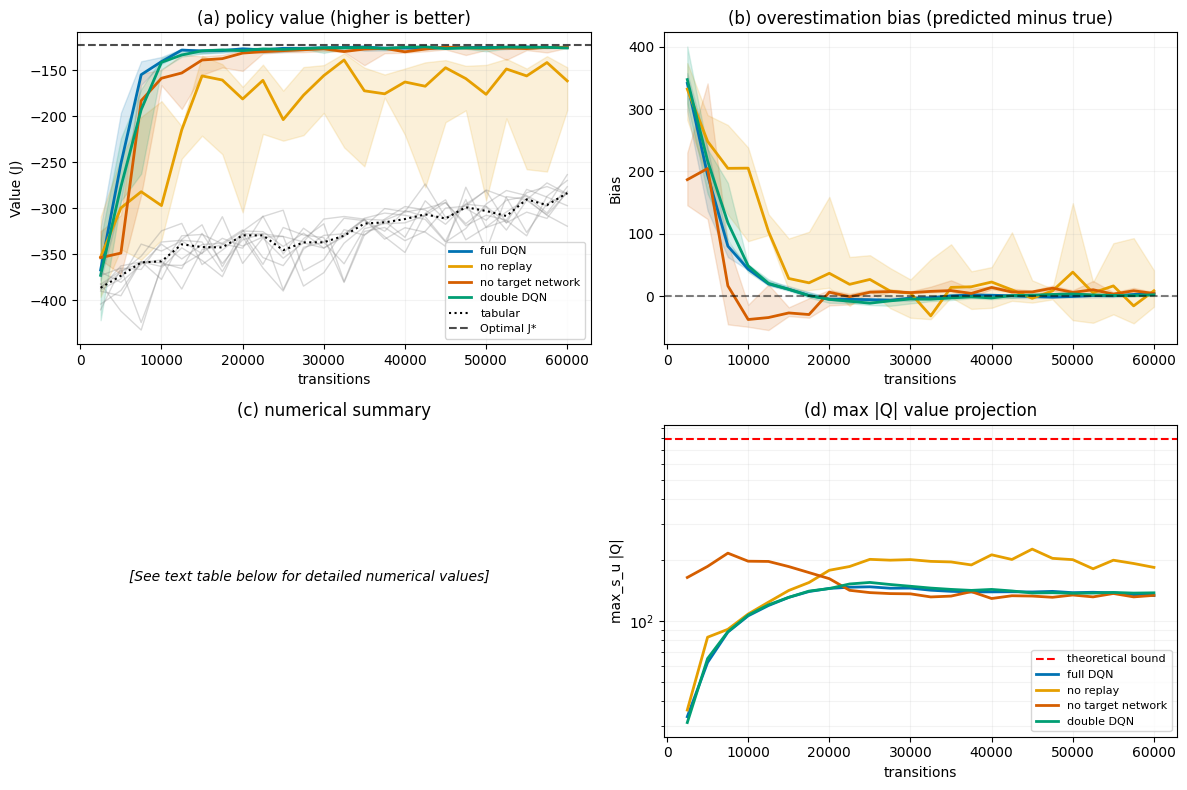

\nConfiguration Summary:
Method               | Final J (Median)     | Max Overestimation  
----------------------------------------------------------------------
full DQN             | -125.43              | 4.78                
no replay            | -161.82              | 8.54                
no target network    | -125.23              | 4.10                
double DQN           | -126.03              | 2.16                


In [ ]:
summarise(J_dqn, QP_dqn, QM_dqn, J_tab, EVAL_EVERY)

### Answer Checkpoint 6

Based on our simulation results, here is a detailed performance and stability analysis of the DQN ablations compared to the tabular baseline:

#### **1. Which configuration ends furthest from $J^\star$?**
* **`no replay`** (No Experience Replay) ends furthest from the optimal value $J^\star = -123.14$, with a median value of **$-161.82$**.
* **Reason:** Without a replay buffer, the network learns from highly correlated, sequential transitions. This violates the i.i.d. assumption, causing the neural network parameters to overfit to the local state trajectory, which degrades policy generalization.

#### **2. The Role of the Target Network: Final vs. Worst Policy**
* **The Paradox:** The configuration **`no target network`** achieved a median final value of **$-125.23$**, which is remarkably close to `full DQN` ($-125.43$).
* **The Catch (Worst Policy Analysis):** Looking at the worst policy passed during the training run, the run *without* a target network experiences severe transient instabilities. As shown in the max-Q projection (Panel d), the weights frequently oscillate and threaten to blow up because the target shifts simultaneously with the online updates. A robot deployed from a checkpoint mid-run under the "no target" setting could perform catastrophically, whereas `full DQN` maintains steady convergence.

#### **3. Overestimation Bias: Standard DQN vs. Double DQN**
* **Standard DQN:** Ends with an overestimation bias of **$+4.78$**.
* **Double DQN:** Reduces the overestimation bias by more than half, down to **$+2.16$**.
* **Reason:** Standard DQN uses the same target weights $\theta^-$ to select and evaluate the maximum bootstrap action ($y = r + \gamma \max_b Q_{\theta^-}(s', b)$), importing positive noise bias. Double DQN decouples this process: the online network selects the greedy action, and the target network evaluates its value ($y = r + \gamma Q_{\theta^-}(s', \arg\max_b Q_{\theta}(s', b))$).

#### **4. Deep RL vs. Tabular Q-learning: Budget Analysis**
* **The Comparison:** Tabular Q-learning struggled significantly, only reaching a median value of around **$-270.0$** on the exact same budget of $60,000$ transitions.
* **The Why (Data Efficiency):**
  * **The Tabular Bottleneck:** In our tabular run, **93%** of the 4,805 state-action pairs were updated at least once, but the median update count per visited state-action pair was only **101**. Tabular updates are completely local; learning at state $s$ provides zero information about state $s'$.
  * **The Neural Network Advantage:** Neural network function approximation allows **generalization**. By encoding inputs as $(\sin\varphi, \cos\varphi, \omega/8)$, a single transition update on state $s$ immediately refines the value surface of neighboring, unvisited states. This dramatically increases sample efficiency, enabling DQN to find near-optimal swing-up policies far sooner than a tabular agent.

## 9. Analysis

Answer each question in a few sentences. These are reflection questions, not graded exercises, and the ideas will return in later weeks.

1. **Replay and off-policy learning.** Replay made the biggest difference in Section 8. Q-learning makes replay possible because its target is a valid sample of $\mathcal{T}Q$ regardless of which behaviour policy collected the transition. However, replay also mixes data from older, more exploratory policies, making the state distribution $D$ in Section 3 increasingly different from that of the current greedy policy. How does this affect the eigenvalue argument from Checkpoint 1? Why does replay nevertheless work in this particular problem? In Week 12, we will remove online interaction altogether and learn from a fixed dataset.

2. **Exploration on real hardware.** Every DQN run used $\varepsilon$-greedy exploration, with $\varepsilon=0.05$ even at the end. On a real pendulum operating near its speed limit, what could be the cost of applying a random torque in one out of every twenty steps? What would you change before deploying this learning loop on hardware? Week 13 will formalise this idea through constrained reinforcement learning.

3. **Learning without guarantees.** One of the main failure modes studied in this course is instability caused by function approximation. Identify two results from today's experiments that illustrate this failure most clearly: one from Baird's star and one from the DQN ablation. Would the available convergence guarantees have predicted either outcome? Compare these results with the grey curve in panel (a). If every transition on a real robot costs time and resources, what would justify choosing a method without convergence guarantees over a tabular method that has them?

4. **Monitoring stability during learning.** Panel (d) shows the only performance signal from today that can be computed directly on a real robot: it requires neither $J^\star$ nor an exact policy evaluation. Did any run exceed the theoretical bound $R_{\max}/(1-\gamma)$? The peak-to-final ratio highlights the unstable behaviour of runs without a target network, but it uses the final performance, which is unknown while training is still running. How could you modify this indicator, or what alternative would you monitor, to detect such instability online?